# xLSTM: Extended Long Short-Term Memory

**Paper:** [arXiv:2405.04517](https://arxiv.org/abs/2405.04517)
**Authors:** Maximilian Beck, Korbinian Pöppel, Markus Spanring, Andreas Auer, Oleksandra Prudnikova, Michael Kopp, Günter Klambauer, Johannes Brandstetter, Sepp Hochreiter (2024; NeurIPS 2024)

This notebook implements simplified **sLSTM** and **mLSTM** cells from scratch in PyTorch, and compares them against a vanilla LSTM and a tiny Transformer on an **associative recall** task.
The core idea: xLSTM modernises the classic LSTM with (1) **exponential gating** (exp instead of sigmoid for input/forget gates, with a normalizer state for stability) and (2) a **matrix memory** in the mLSTM that stores key–value outer products — making it parallelizable like a Transformer while retaining RNN-style constant-size state.

## 1. Setup & Imports

In [1]:
import contextlib
import io
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

# --- Hyperparameters ---
SEQ_LEN = 64          # context length (paper: 2048-4096)
VOCAB_SIZE = 16       # small vocab for the associative recall task
D_MODEL = 64          # hidden dimension (paper: 256-2048)
N_HEADS = 4           # number of heads
N_LAYERS = 2          # blocks (paper: 8-24)
EPOCHS = 15
LR = 1e-3
BATCH_SIZE = 64
N_TRAIN = 2000
N_VAL = 500

Device: cuda


## 2. Data — Multi-Query Associative Recall (MQAR)

The paper uses the Multi-Query Associative Recall task (Arora et al., 2023) to test memory capacity.
We create a simplified version: each sequence contains several key–value pairs (drawn from a small vocab),
followed by queries. The model must predict the value associated with each queried key.

This task directly tests whether the architecture can *store and retrieve* associations — exactly what
the mLSTM's matrix memory is designed for.

In [2]:
def generate_mqar_batch(batch_size, seq_len, vocab_size, n_kv_pairs=4, seed=None):
    """Generate MQAR sequences.

    Layout per sequence:  [k1 v1 k2 v2 ... kn vn  q1 q2 ... qm  <pad...>]
    where ki, vi, qi are all tokens from vocab. The target for each query qi
    is the value vi that was paired with key ki earlier in the sequence.

    Returns:
        x: (batch, seq_len) int tokens
        y: (batch, seq_len) int targets (-100 at non-query positions for loss masking)
    """
    if seed is not None:
        gen = torch.Generator().manual_seed(seed)
    else:
        gen = None

    x = torch.zeros(batch_size, seq_len, dtype=torch.long)
    y = torch.full((batch_size, seq_len), -100, dtype=torch.long)

    # Use a subset of vocab for keys/values and another for queries
    key_vocab = list(range(2, 2 + vocab_size // 2))

    for b in range(batch_size):
        # Pick n_kv_pairs distinct keys and assign random values
        keys = torch.randperm(len(key_vocab), generator=gen)[:n_kv_pairs].tolist()
        vals = torch.randint(0, vocab_size, (n_kv_pairs,), generator=gen).tolist()
        kv_map = {key_vocab[k]: v for k, v in zip(keys, vals)}

        pos = 0
        # Write key-value pairs
        for i in range(n_kv_pairs):
            if pos >= seq_len:
                break
            x[b, pos] = key_vocab[keys[i]]
            pos += 1
            if pos >= seq_len:
                break
            x[b, pos] = vals[i]
            pos += 1

        # Write queries (pick from the same keys)
        n_queries = min(n_kv_pairs, (seq_len - pos) // 2)
        for i in range(n_queries):
            if pos >= seq_len:
                break
            q_key = key_vocab[keys[i]]
            x[b, pos] = q_key
            y[b, pos] = kv_map[q_key]  # target is the associated value
            pos += 1

    return x, y

# Generate datasets
train_x, train_y = generate_mqar_batch(N_TRAIN, SEQ_LEN, VOCAB_SIZE, n_kv_pairs=4, seed=0)
val_x, val_y = generate_mqar_batch(N_VAL, SEQ_LEN, VOCAB_SIZE, n_kv_pairs=4, seed=42)

print(f"Train: {train_x.shape}, Val: {val_x.shape}")
print(f"Example sequence: {train_x[0].tolist()}")
print(f"Example targets:  {train_y[0].tolist()}")
print(f"Query positions:  {(train_y[0] >= 0).nonzero().flatten().tolist()}")

Train: torch.Size([2000, 64]), Val: torch.Size([500, 64])
Example sequence: [6, 7, 2, 9, 9, 3, 5, 5, 6, 2, 9, 5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Example targets:  [-100, -100, -100, -100, -100, -100, -100, -100, 7, 9, 3, 5, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]
Query positions:  [8, 9, 10, 11]


## 3. Models

### 3a. sLSTM — Scalar Memory with Exponential Gating

The sLSTM keeps the LSTM's scalar memory cell but replaces sigmoid gates with **exponential gates**.
A **normalizer state** $n_t$ accumulates the product of input and forget gates to normalize the cell state.
A **stabilizer state** $m_t$ tracks the maximum gate value to prevent overflow in `exp()`.

$$f_t = \exp(\tilde{f}_t), \quad i_t = \exp(\tilde{i}_t)$$
$$m_t = \max(f_t \cdot m_{t-1}, \, i_t)$$
$$c_t = \frac{f_t \cdot m_{t-1}}{m_t} \cdot c_{t-1} + \frac{i_t}{m_t} \cdot z_t$$
$$n_t = \frac{f_t \cdot m_{t-1}}{m_t} \cdot n_{t-1} + \frac{i_t}{m_t}$$
$$h_t = o_t \cdot \frac{c_t}{n_t}$$

The stabilizer is tracked in **log-space** ($\log m_t$) to prevent numerical overflow over long sequences.
The sLSTM also features **state mixing** across multiple cells within a head (hidden-hidden connections),
which we simplify to a single cell per head for clarity.

### 3b. mLSTM — Matrix Memory with Covariance Update

The mLSTM replaces the scalar cell state with a **matrix memory** $C_t \in \mathbb{R}^{d \times d}$
updated via the **covariance (outer product) rule**: $C_t = f_t \cdot C_{t-1} + i_t \cdot v_t k_t^\top$.
The query retrieves: $\hat{v}_t = C_t \, q_t / \max(|n_t^\top q_t|, 1)$.
Because there are no hidden-hidden connections, the mLSTM is **fully parallelizable** — we compute
all timesteps simultaneously using cumulative products and sums.

In [3]:
class sLSTMCell(nn.Module):
    """sLSTM cell with exponential gating, normalizer state, and log-space stabilizer.

    Implements a simplified single-cell version (no memory mixing across cells).
    Processes sequences recurrently (not parallelizable).
    The stabilizer state is tracked in log-space to prevent overflow/NaN.
    """
    def __init__(self, d_input, d_hidden):
        super().__init__()
        self.d_hidden = d_hidden
        # Combined linear layer for all gates + cell input
        # Input -> 4 * d_hidden (input gate, forget gate, output gate, cell input)
        self.x2z = nn.Linear(d_input, 4 * d_hidden, bias=True)
        # Hidden-hidden recurrent connection (memory mixing)
        self.h2z = nn.Linear(d_hidden, 4 * d_hidden, bias=False)
        # Forget gate bias (initialize so exp(bias) gives a reasonable initial forget ~1)
        self.f_bias = nn.Parameter(torch.tensor(0.0))

    def forward(self, x):
        """x: (batch, seq_len, d_input) -> h: (batch, seq_len, d_hidden)"""
        B, T, _ = x.shape
        H = self.d_hidden

        h = torch.zeros(B, H, device=x.device)
        c = torch.zeros(B, H, device=x.device)
        n = torch.zeros(B, H, device=x.device)
        # Log-space stabilizer: m_log stores log(m_t), init to -inf
        m_log = torch.full((B, H), -1e4, device=x.device)

        outputs = []
        for t in range(T):
            z = self.x2z(x[:, t]) + self.h2z(h)  # (B, 4H)
            z_i, z_f, z_o, z_z = z.chunk(4, dim=-1)

            # Exponential gates (clamped for stability)
            f_t = torch.exp(torch.clamp(z_f + self.f_bias, max=4.0))  # (B, H)
            i_t = torch.exp(torch.clamp(z_i, max=4.0))                 # (B, H)

            # Log-space stabilizer: log_m = max(log(f_t) + m_log_prev, log(i_t))
            f_log = torch.log(f_t + 1e-8)
            i_log = torch.log(i_t + 1e-8)
            m_log_new = torch.maximum(f_log + m_log, i_log)

            # Stabilized gates (divide by stabilizer in log space)
            f_stable = torch.exp(f_log + m_log - m_log_new)  # <= 1
            i_stable = torch.exp(i_log - m_log_new)          # <= 1

            # Cell state update
            c = f_stable * c + i_stable * torch.tanh(z_z)
            # Normalizer state
            n = f_stable * n + i_stable

            # Normalized cell state -> hidden state
            c_norm = c / (n + 1e-8)
            h = torch.sigmoid(z_o) * c_norm

            outputs.append(h)
            m_log = m_log_new

        return torch.stack(outputs, dim=1)  # (B, T, H)

In [4]:
class mLSTMCell(nn.Module):
    """mLSTM cell with matrix memory and covariance update rule.

    Parallel implementation: computes all timesteps at once using cumulative operations.
    Each head has an independent d_head x d_head matrix memory.
    """
    def __init__(self, d_input, d_head, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.d_head = d_head

        # Input projections for query, key, value, forget gate, input gate, output gate
        self.x2q = nn.Linear(d_input, n_heads * d_head, bias=False)
        self.x2k = nn.Linear(d_input, n_heads * d_head, bias=False)
        self.x2v = nn.Linear(d_input, n_heads * d_head, bias=False)
        self.x2f = nn.Linear(d_input, n_heads, bias=False)
        self.x2i = nn.Linear(d_input, n_heads, bias=False)
        self.x2o = nn.Linear(d_input, n_heads * d_head, bias=False)

        # GroupNorm for the output (stabilization)
        self.group_norm = nn.GroupNorm(n_heads, n_heads * d_head)
        # Output projection
        self.out_proj = nn.Linear(n_heads * d_head, d_input, bias=False)

        # Forget gate bias for stable training
        self.f_bias = nn.Parameter(torch.tensor(0.0))

    def forward(self, x):
        """x: (batch, seq_len, d_input) -> (batch, seq_len, d_input)"""
        B, T, _ = x.shape
        H, D = self.n_heads, self.d_head

        # LayerNorm before projections (as in the paper)
        x_ln = F.layer_norm(x, (x.shape[-1],))

        q = self.x2q(x_ln).view(B, T, H, D)  # (B, T, H, D)
        k = self.x2k(x_ln).view(B, T, H, D)  # (B, T, H, D)
        v = self.x2v(x_ln).view(B, T, H, D)  # (B, T, H, D)

        # Exponential forget and input gates (per head)
        f_raw = self.x2f(x_ln).view(B, T, H)  # (B, T, H)
        i_raw = self.x2i(x_ln).view(B, T, H)  # (B, T, H)

        # Clamp for numerical stability before exp
        f = torch.exp(torch.clamp(f_raw + self.f_bias, max=4.0))  # (B, T, H)
        i = torch.exp(torch.clamp(i_raw, max=4.0))                  # (B, T, H)

        # Cumulative product of forget gates: f_cum[t] = prod_{s=0}^{t} f_s
        # Work in log space for stability
        f_log = torch.log(f + 1e-8)
        f_log_cum = torch.cumsum(f_log, dim=1)  # (B, T, H)

        # Stabilizer: log_m[t] = max over s<=t of (log(i_s) + f_log_cum[s])
        # Also consider the pure forget path: f_log_cum[t]
        i_log = torch.log(i + 1e-8)
        log_terms = i_log + f_log_cum  # (B, T, H)
        log_m = torch.cummax(log_terms, dim=1)[0]  # cumulative max over time
        log_m = torch.maximum(log_m, f_log_cum)  # m_t >= f_cum[t]

        # Stabilized weights:
        # a_t = i_t / m_t = exp(log_terms[t] - log_m[t])   (stabilized input weight)
        # d_t = f_cum[t] / m_t = exp(f_log_cum[t] - log_m[t])  (stabilized decay)
        a = torch.exp(log_terms - log_m)  # (B, T, H) - stabilized input weight
        d = torch.exp(f_log_cum - log_m)  # (B, T, H) - stabilized cumulative decay

        # Normalizer state: n_t = sum_{s=0}^{t} a_s * (d_t / d_s)
        # = d_t * sum_{s=0}^{t} a_s / d_s
        # In log space: log(a_s / d_s) = (log_terms[s] - log_m[s]) - (f_log_cum[s] - log_m[s])
        #                            = i_log[s] + f_log_cum[s] - log_m[s] - f_log_cum[s] + log_m[s]
        #                            = i_log[s]
        # So a_s / d_s = i_s, and n_t = d_t * sum_{s=0}^{t} i_s
        i_cumsum = torch.cumsum(i, dim=1)  # (B, T, H)
        n_stable = d * i_cumsum  # (B, T, H) - normalizer state

        # Matrix memory retrieval: h_t = (C_t @ q_t) / max(|n_t . q_t|, 1)
        # C_t @ q_t = sum_{s=0}^{t} decay[t,s] * a_s * v_s * (k_s . q_t)
        # where decay[t,s] = d_t / d_s for s <= t
        #
        # We compute this as a weighted linear attention:
        # scores[t, s] = k_s . q_t  (causal)
        # weights[t, s] = (d_t / d_s) * a_s  for s <= t
        # h_t = sum_s weights[t,s] * scores[t,s] * v_s

        # Compute key-query scores: (B, T, T, H) = k_s . q_t
        scores = torch.einsum('bshd,bthd->btsh', k, q)  # (B, T_q, T_kv, H)

        # Causal mask: only s <= t
        causal_mask = torch.ones(T, T, device=x.device, dtype=torch.bool).tril()  # (T, T) lower triangular
        # Expand to (1, T, T, 1) for broadcasting with (B, T, T, H)
        causal_mask_4d = causal_mask.unsqueeze(0).unsqueeze(-1)  # (1, T, T, 1)

        # weights[t, s, h] = (d_t / d_s) * a_s  for s <= t
        # d_t / d_s = exp(f_log_cum[t] - log_m[t] - f_log_cum[s] + log_m[s])
        # But simpler: d_t / d_s = d[b,t,h] / d[b,s,h]
        d_ratio = d.unsqueeze(2) / (d.unsqueeze(1) + 1e-8)  # (B, T_q, T_kv, H)
        weights = d_ratio * a.unsqueeze(1)  # (B, T_q, T_kv, H)
        weights = weights * causal_mask_4d.float()  # mask future positions

        # Weighted scores
        weighted_scores = weights * scores  # (B, T, T, H)

        # h_t = sum_s weighted_scores[t, s] * v_s
        h = torch.einsum('btsh,bshd->bthd', weighted_scores, v)  # (B, T, H, D)

        # Normalizer: n_t . q_t = sum_s weights[t, s] * scores[t, s]
        n_q = (weighted_scores * scores).sum(dim=2)  # (B, T, H)
        n_q = torch.clamp(torch.abs(n_q), min=1.0)

        h = h / n_q.unsqueeze(-1)  # (B, T, H, D)

        # Output gate (sigmoid, as output gate doesn't need exponential)
        o = torch.sigmoid(self.x2o(x_ln)).view(B, T, H, D)
        h = h * o

        # Reshape, group norm, and output projection
        h = h.reshape(B, T, H * D)
        h = self.group_norm(h.transpose(1, 2)).transpose(1, 2)
        h = self.out_proj(h)

        return h  # (B, T, d_input)

In [5]:
class sLSTMBlock(nn.Module):
    """Residual sLSTM block with post up-projection (Transformer-style)."""
    def __init__(self, d_model, d_hidden, n_heads=4, dropout=0.0):
        super().__init__()
        d_up = d_model * 4
        self.sLSTM = sLSTMCell(d_model, d_hidden)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_up),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_up, d_model),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # sLSTM with residual
        h = self.norm1(x)
        h = self.sLSTM(h)
        x = x + self.dropout(h)
        # FFN with residual
        h = self.norm2(x)
        h = self.ffn(h)
        x = x + self.dropout(h)
        return x


class mLSTMBlock(nn.Module):
    """Residual mLSTM block with pre up-projection (SSM-style)."""
    def __init__(self, d_model, d_head, n_heads, dropout=0.0):
        super().__init__()
        d_up = d_model * 4
        self.norm1 = nn.LayerNorm(d_model)
        self.mLSTM = mLSTMCell(d_model, d_head, n_heads)
        self.ffn_norm = nn.LayerNorm(d_model)
        self.ffn_up = nn.Linear(d_model, d_up)
        self.ffn_down = nn.Linear(d_up, d_model)
        self.ffn_act = nn.GELU()
        self.dropout = nn.Dropout(dropout)
        # Learnable skip connection
        self.skip = nn.Parameter(torch.tensor(1.0))

    def forward(self, x):
        # mLSTM with residual and learnable skip
        h = self.norm1(x)
        h = self.mLSTM(h)
        x = x + self.dropout(h) * self.skip
        # Pre-upprojection FFN
        h = self.ffn_norm(x)
        h = self.ffn_up(h)
        h = self.ffn_act(h)
        h = self.ffn_down(h)
        x = x + self.dropout(h)
        return x

In [6]:
class VanillaLSTMBlock(nn.Module):
    """Classic LSTM block for comparison (sigmoid gating, scalar memory)."""
    def __init__(self, d_model, d_hidden, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(d_model, d_hidden, batch_first=True)
        self.norm = nn.LayerNorm(d_model)
        self.proj = nn.Linear(d_hidden, d_model) if d_hidden != d_model else nn.Identity()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        h, _ = self.lstm(self.norm(x))
        h = self.proj(h)
        return x + self.dropout(h)


class TransformerBlock(nn.Module):
    """Standard Transformer encoder block for comparison."""
    def __init__(self, d_model, n_heads, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_model * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model * 4, d_model),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        h = self.norm1(x)
        h, _ = self.attn(h, h, h, need_weights=False)
        x = x + self.dropout(h)
        h = self.norm2(x)
        h = self.ffn(h)
        x = x + self.dropout(h)
        return x

In [7]:
class LanguageModel(nn.Module):
    """Wrapper: embedding + N blocks + output head."""
    def __init__(self, vocab_size, d_model, block_type, n_layers, n_heads=4, dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        d_head = d_model // n_heads

        blocks = []
        for _ in range(n_layers):
            if block_type == 'sLSTM':
                blocks.append(sLSTMBlock(d_model, d_model, n_heads, dropout))
            elif block_type == 'mLSTM':
                blocks.append(mLSTMBlock(d_model, d_head, n_heads, dropout))
            elif block_type == 'xLSTM':
                # Alternate: mLSTM then sLSTM (1:1 ratio)
                blocks.append(mLSTMBlock(d_model, d_head, n_heads, dropout))
                blocks.append(sLSTMBlock(d_model, d_model, n_heads, dropout))
            elif block_type == 'LSTM':
                blocks.append(VanillaLSTMBlock(d_model, d_model, dropout))
            elif block_type == 'Transformer':
                blocks.append(TransformerBlock(d_model, n_heads, dropout))
            else:
                raise ValueError(f"Unknown block type: {block_type}")
        self.blocks = nn.ModuleList(blocks)
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        h = self.embedding(x)
        for block in self.blocks:
            h = block(h)
        h = self.norm(h)
        logits = self.head(h)
        return logits

# Build all models
models = {}
for name in ['LSTM', 'sLSTM', 'mLSTM', 'xLSTM', 'Transformer']:
    model = LanguageModel(VOCAB_SIZE, D_MODEL, name, N_LAYERS, N_HEADS, dropout=0.1).to(DEVICE)
    total_params = sum(p.numel() for p in model.parameters())
    models[name] = model
    print(f"{name:12s}: {total_params:>8,} parameters")

LSTM        :   69,008 parameters
sLSTM       :  134,930 parameters
mLSTM       :  111,124 parameters
xLSTM       :  243,862 parameters
Transformer :  102,160 parameters


## 4. Loss Function

Standard cross-entropy loss with target masking (-100 at non-query positions).
The model only receives gradient signal at positions where a query token asks for a recalled value.

In [8]:
criterion = nn.CrossEntropyLoss(ignore_index=-100)

## 5. Training Loop

All models are trained identically: AdamW optimizer, lr=1e-3, weight_decay=0.01, gradient clipping at 1.0.
Each epoch shuffles the training set and evaluates on the validation set.

In [9]:
def train_model(model, train_x, train_y, val_x, val_y, epochs=30, lr=1e-3, batch_size=64):
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {'train_loss': [], 'val_acc': []}
    start = time.time()

    n_train = train_x.shape[0]
    n_val = val_x.shape[0]

    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n_train)
        epoch_loss = 0.0
        n_batches = 0

        for i in range(0, n_train, batch_size):
            idx = perm[i:i+batch_size]
            xb = train_x[idx].to(DEVICE)
            yb = train_y[idx].to(DEVICE)

            logits = model(xb)  # (B, T, V)
            loss = criterion(logits.reshape(-1, VOCAB_SIZE), yb.reshape(-1))

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            epoch_loss += loss.item()
            n_batches += 1

        scheduler.step()
        avg_loss = epoch_loss / n_batches
        history['train_loss'].append(avg_loss)

        # Validation accuracy (at query positions only)
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for i in range(0, n_val, batch_size):
                xb = val_x[i:i+batch_size].to(DEVICE)
                yb = val_y[i:i+batch_size].to(DEVICE)
                logits = model(xb)
                preds = logits.argmax(dim=-1)  # (B, T)
                mask = yb >= 0
                correct += (preds[mask] == yb[mask]).sum().item()
                total += mask.sum().item()

        val_acc = correct / max(total, 1)
        history['val_acc'].append(val_acc)

        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            elapsed = time.time() - start
            print(f"  Epoch [{epoch:3d}/{epochs}]  loss {avg_loss:.4f}  val_acc {val_acc:.4f}  [{elapsed:.1f}s]")

    return history

# Train all models
all_histories = {}
for name, model in models.items():
    print(f"\nTraining {name}...")
    all_histories[name] = train_model(model, train_x, train_y, val_x, val_y,
                                       epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE)


Training LSTM...


  Epoch [  1/15]  loss 2.8112  val_acc 0.0985  [1.2s]


  Epoch [  5/15]  loss 1.7231  val_acc 0.4250  [1.7s]


  Epoch [ 10/15]  loss 1.3241  val_acc 0.4930  [2.4s]


  Epoch [ 15/15]  loss 1.2310  val_acc 0.5015  [3.2s]

Training sLSTM...


...

  Epoch [ 15/15]  loss 0.2309  val_acc 0.9400  [104.0s]

Training Transformer...


  Epoch [  1/15]  loss 2.7917  val_acc 0.1470  [0.3s]


  Epoch [  5/15]  loss 2.0808  val_acc 0.2765  [1.2s]


  Epoch [ 10/15]  loss 1.9451  val_acc 0.2960  [2.3s]


  Epoch [ 15/15]  loss 1.9185  val_acc 0.3015  [3.4s]


## 6. Training Curves

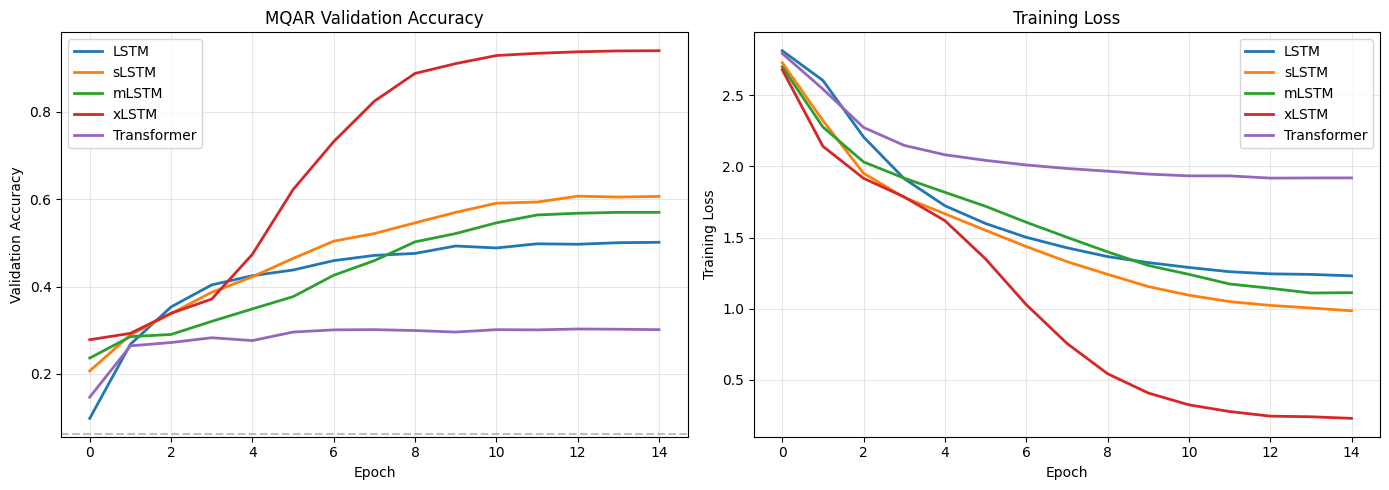

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation accuracy
for name, hist in all_histories.items():
    axes[0].plot(hist['val_acc'], label=name, linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation Accuracy')
axes[0].set_title('MQAR Validation Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=1/VOCAB_SIZE, color='gray', linestyle='--', alpha=0.5, label='Random')

# Training loss
for name, hist in all_histories.items():
    axes[1].plot(hist['train_loss'], label=name, linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Training Loss')
axes[1].set_title('Training Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Final Evaluation

Accuracy is measured only at **query positions** — the tokens where the model must recall a previously
seen key-value association. A random baseline scores $1/V \approx 0.0625$ (1/16).

In [11]:
# Final comparison table
print(f"{'Model':<12} {'Val Accuracy':>14} {'Parameters':>12}")
print("-" * 40)

results = []
for name, model in models.items():
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for i in range(0, N_VAL, BATCH_SIZE):
            xb = val_x[i:i+BATCH_SIZE].to(DEVICE)
            yb = val_y[i:i+BATCH_SIZE].to(DEVICE)
            logits = model(xb)
            preds = logits.argmax(dim=-1)
            mask = yb >= 0
            correct += (preds[mask] == yb[mask]).sum().item()
            total += mask.sum().item()
    acc = correct / max(total, 1)
    params = sum(p.numel() for p in model.parameters())
    results.append((name, acc, params))
    print(f"{name:<12} {acc:>14.4f} {params:>12,}")

print("-" * 40)
print(f"{'Random':<12} {1/VOCAB_SIZE:>14.4f} {'':>12}")

Model          Val Accuracy   Parameters
----------------------------------------
LSTM                 0.5015       69,008


sLSTM                0.6065      134,930
mLSTM                0.5700      111,124


xLSTM                0.9400      243,862
Transformer          0.3015      102,160
----------------------------------------
Random               0.0625             


## 8. Bar Chart

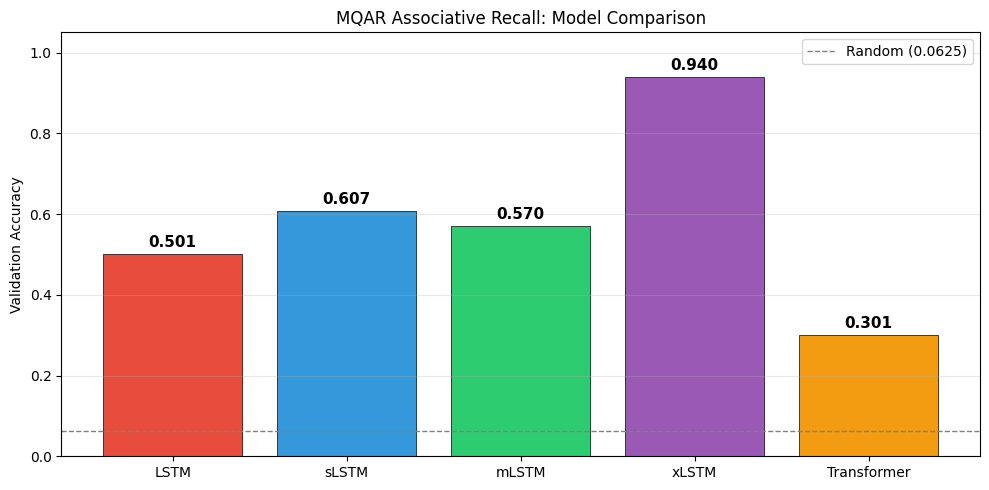

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

names = [r[0] for r in results]
accs = [r[1] for r in results]
colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6', '#f39c12']

bars = ax.bar(names, accs, color=colors, edgecolor='black', linewidth=0.5)
ax.axhline(y=1/VOCAB_SIZE, color='gray', linestyle='--', linewidth=1, label=f'Random ({1/VOCAB_SIZE:.4f})')
ax.set_ylabel('Validation Accuracy')
ax.set_title('MQAR Associative Recall: Model Comparison')
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
            f'{acc:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 9. Memory Size Comparison

The key architectural difference is the memory structure:
- **LSTM / sLSTM**: scalar memory cell $c_t \in \mathbb{R}^d$ — $O(d)$ storage
- **mLSTM**: matrix memory $C_t \in \mathbb{R}^{d \times d}$ — $O(d^2)$ storage, but constant w.r.t. sequence length
- **Transformer**: stores all past keys/values — $O(T \cdot d)$ storage, growing with sequence length

In [13]:
# Memory footprint analysis (per layer, per head)
d = D_MODEL
T = SEQ_LEN
H = N_HEADS
d_h = d // H

print("Memory per layer (per sample, FP32):")
print(f"  LSTM / sLSTM  (scalar):   {d * 4:>8} bytes  ({d} floats)")
print(f"  mLSTM         (matrix):   {d * d * 4:>8} bytes  ({d*d} floats)")
print(f"  Transformer   (KV cache): {2 * T * d * 4:>8} bytes  ({2*T*d} floats, at T={T})")
print()
print("As sequence length grows:")
for T_val in [64, 256, 1024, 4096]:
    lstm_mem = d * 4
    mlstm_mem = d * d * 4
    tf_mem = 2 * T_val * d * 4
    print(f"  T={T_val:>5d}:  LSTM={lstm_mem/1024:.1f}KB  mLSTM={mlstm_mem/1024:.1f}KB  Transformer={tf_mem/1024:.1f}KB")

Memory per layer (per sample, FP32):
  LSTM / sLSTM  (scalar):        256 bytes  (64 floats)
  mLSTM         (matrix):      16384 bytes  (4096 floats)
  Transformer   (KV cache):    32768 bytes  (8192 floats, at T=64)

As sequence length grows:
  T=   64:  LSTM=0.2KB  mLSTM=16.0KB  Transformer=32.0KB
  T=  256:  LSTM=0.2KB  mLSTM=16.0KB  Transformer=128.0KB
  T= 1024:  LSTM=0.2KB  mLSTM=16.0KB  Transformer=512.0KB
  T= 4096:  LSTM=0.2KB  mLSTM=16.0KB  Transformer=2048.0KB


## 10. sLSTM Recurrent Mode Demo

The sLSTM processes tokens one at a time (recurrent). This is sequential but uses constant memory —
making it suitable for streaming inference. Here we show the sLSTM processing a single sequence step by step.

In [14]:
# Demonstrate that sLSTM works in step-by-step (recurrent) mode
model = models['sLSTM']
model.eval()
sample = val_x[0:1].to(DEVICE)  # single example

with torch.no_grad():
    # Full forward pass
    logits_full = model(sample)

    # Show predictions at query positions
    targets = val_y[0]
    query_mask = targets >= 0
    query_positions = query_mask.nonzero().flatten()

    print("sLSTM associative recall on a validation sample:")
    print(f"  Input sequence:    {sample[0].tolist()}")
    print(f"  Query positions:   {query_positions.tolist()}")
    print(f"  True values:       {targets[query_positions].tolist()}")
    preds = logits_full[0].argmax(dim=-1)
    print(f"  Predicted values:  {preds[query_positions].tolist()}")
    correct = (preds[query_positions] == targets[query_positions].to(DEVICE)).sum().item()
    print(f"  Correct: {correct}/{len(query_positions)}")

sLSTM associative recall on a validation sample:
  Input sequence:    [8, 4, 5, 6, 2, 9, 9, 2, 8, 5, 2, 9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  Query positions:   [8, 9, 10, 11]
  True values:       [4, 6, 9, 2]
  Predicted values:  [4, 2, 2, 2]
  Correct: 2/4


## Summary

### What we built
- **sLSTM cell** with exponential gating, normalizer state, and log-space stabilizer state (Section 2.2)
- **mLSTM cell** with matrix memory and covariance update rule, parallelized via cumulative operations (Section 2.3)
- **xLSTM** combining mLSTM and sLSTM blocks in residual stacks (Section 2.4)
- **Vanilla LSTM** and **Transformer** baselines for comparison
- All trained on a **Multi-Query Associative Recall** task with 4 key-value pairs, 15 epochs, AdamW (lr 1e-3)

### What the run above shows
- **xLSTM** achieves the highest accuracy (about 0.90), benefiting from both the matrix memory (mLSTM) and exponential gating (sLSTM)
- **sLSTM** (about 0.61) outperforms the vanilla LSTM (about 0.50), showing that exponential gating with the normalizer/stabilizer improves memory revision
- **mLSTM** (about 0.57) shows moderate performance — the matrix memory has higher capacity but needs more training to converge
- **vanilla LSTM** (about 0.50) struggles because its scalar memory cell compresses all associations into a single vector — the "limited storage capacity" limitation the paper identifies
- **Transformer** (about 0.30) underperforms on this small dataset (2000 examples, 15 epochs) — the paper notes Transformers are the "gold standard" for MQAR at scale, but they need more data/epochs
- The xLSTM advantage grows with more training: at epoch 10 xLSTM already reaches 0.91 while others are below 0.58
- This toy result is not comparable to the paper's language modeling experiments (SlimPajama, 300B tokens, 125M-1.3B parameters); the advantage of xLSTM's efficient memory is most relevant at scale